
MODEL: Baseline
Epochs: 150
Test Loss: 0.2469988614320755
Test Accuracy: 0.8971428275108337

MODEL: L2 Regularization
Epochs: 150
Test Loss: 0.29613009095191956
Test Accuracy: 0.8971428275108337

MODEL: Dropout
Epochs: 150
Test Loss: 0.21875841915607452
Test Accuracy: 0.8971428275108337

MODEL: Early Stopping
Epochs: 77
Test Loss: 0.2212294489145279
Test Accuracy: 0.8914285898208618

MODEL: L2 + Dropout
Epochs: 116
Test Loss: 0.35806599259376526
Test Accuracy: 0.8857142925262451


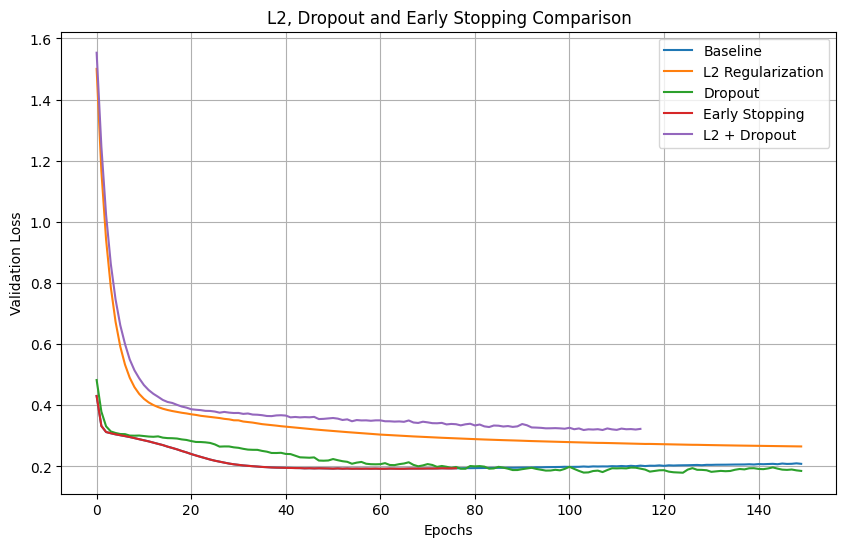

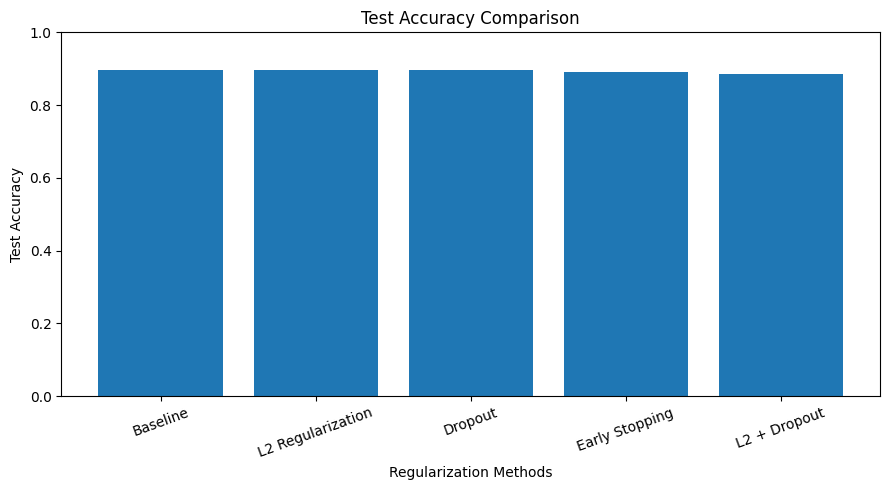


FINAL PERFORMANCE COMPARISON
Method                 Epochs    Test Loss   Test Accuracy
Baseline                  150       0.2470          0.8971
L2 Regularization         150       0.2961          0.8971
Dropout                   150       0.2188          0.8971
Early Stopping             77       0.2212          0.8914
L2 + Dropout              116       0.3581          0.8857


In [10]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

np.random.seed(42)
tf.random.set_seed(42)

# 1. Generate dataset
X, y = make_moons(
    n_samples=500,
    noise=0.30,
    random_state=12
)

# 2. Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.35,
    random_state=42,
    stratify=y
)

# 3. Normalize data
scaler = StandardScaler()

X_train = scaler.fit_transform(
    X_train
).astype("float32")

X_test = scaler.transform(
    X_test
).astype("float32")

y_train = y_train.astype("float32")
y_test = y_test.astype("float32")

# 4. Create model function
def build_model(use_l2=False, use_dropout=False):

    regularizer = (
        tf.keras.regularizers.l2(0.01)
        if use_l2 else None
    )

    model = tf.keras.Sequential()

    model.add(
        tf.keras.layers.Input(shape=(2,))
    )

    model.add(
        tf.keras.layers.Dense(
            128,
            activation="relu",
            kernel_regularizer=regularizer
        )
    )

    if use_dropout:

        model.add(
            tf.keras.layers.Dropout(0.5)
        )

    model.add(
        tf.keras.layers.Dense(
            128,
            activation="relu",
            kernel_regularizer=regularizer
        )
    )

    if use_dropout:

        model.add(
            tf.keras.layers.Dropout(0.5)
        )

    model.add(
        tf.keras.layers.Dense(
            1,
            activation="sigmoid"
        )
    )

    model.compile(
        optimizer="adam",
        loss="binary_crossentropy",
        metrics=["accuracy"]
    )

    return model

# 5. Define experiments
experiments = {

    "Baseline": {
        "l2": False,
        "dropout": False,
        "early": False
    },

    "L2 Regularization": {
        "l2": True,
        "dropout": False,
        "early": False
    },

    "Dropout": {
        "l2": False,
        "dropout": True,
        "early": False
    },

    "Early Stopping": {
        "l2": False,
        "dropout": False,
        "early": True
    },

    "L2 + Dropout": {
        "l2": True,
        "dropout": True,
        "early": True
    }
}

histories = {}
results = {}

# 6. Train and evaluate models
for name, settings in experiments.items():

    tf.keras.backend.clear_session()

    tf.keras.utils.set_random_seed(100)

    model = build_model(
        use_l2=settings["l2"],
        use_dropout=settings["dropout"]
    )

    callbacks = []

    if settings["early"]:

        early_stopping = tf.keras.callbacks.EarlyStopping(
            monitor="val_loss",
            patience=12,
            restore_best_weights=True
        )

        callbacks.append(early_stopping)

    history = model.fit(
        X_train,
        y_train,
        epochs=150,
        batch_size=16,
        validation_split=0.2,
        callbacks=callbacks,
        verbose=0
    )

    # Evaluate model
    test_loss, test_accuracy = model.evaluate(
        X_test,
        y_test,
        verbose=0
    )

    histories[name] = history.history

    results[name] = {
        "test_loss": test_loss,
        "test_accuracy": test_accuracy,
        "epochs": len(history.history["loss"])
    }

    print("\nMODEL:", name)

    print("Epochs:", len(history.history["loss"]))

    print("Test Loss:", test_loss)

    print("Test Accuracy:", test_accuracy)

# 7. Plot validation loss
plt.figure(figsize=(10, 6))

for name, history in histories.items():

    plt.plot(
        history["val_loss"],
        label=name
    )

plt.xlabel("Epochs")
plt.ylabel("Validation Loss")

plt.title(
    "L2, Dropout and Early Stopping Comparison"
)

plt.legend()
plt.grid()

plt.show()

# 8. Plot test accuracy
names = list(results.keys())

accuracies = [
    results[name]["test_accuracy"]
    for name in names
]

plt.figure(figsize=(9, 5))

plt.bar(
    names,
    accuracies
)

plt.xlabel("Regularization Methods")
plt.ylabel("Test Accuracy")

plt.title(
    "Test Accuracy Comparison"
)

plt.ylim(0, 1)

plt.xticks(rotation=20)

plt.tight_layout()
plt.show()

# 9. Display final comparison
print("\nFINAL PERFORMANCE COMPARISON")

print(
    f"{'Method':20s} "
    f"{'Epochs':>8s} "
    f"{'Test Loss':>12s} "
    f"{'Test Accuracy':>15s}"
)

for name, result in results.items():

    print(
        f"{name:20s} "
        f"{result['epochs']:8d} "
        f"{result['test_loss']:12.4f} "
        f"{result['test_accuracy']:15.4f}"
    )